/content/drive/MyDrive/Inteligencia Artificial/Rfacial


Saving WIN_20251030_09_07_56_Pro.jpg to WIN_20251030_09_07_56_Pro (1).jpg


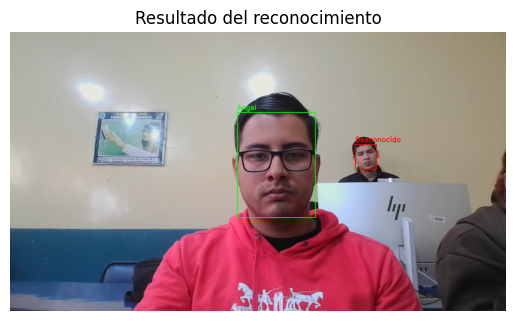

In [4]:
%cd /content/drive/MyDrive/Inteligencia Artificial/Rfacial
# ✅ 1. Instalar dependencias
!pip install deepface

# ✅ 2. Importar librerías
from deepface import DeepFace
from google.colab import files
import zipfile, os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_distances

# ✅ 3. Subir y descomprimir base de datos

# ✅ Ruta a tu base en Drive
db_path = "/content/drive/MyDrive/Inteligencia Artificial/Rfacial/data"

# ✅ Cargar embeddings de la base
db_embeddings = []
db_names = []

for person in os.listdir(db_path):
    person_folder = os.path.join(db_path, person)
    if os.path.isdir(person_folder):
        for img in os.listdir(person_folder):
            full_path = os.path.join(person_folder, img)
            try:
                emb = DeepFace.represent(img_path=full_path, model_name="ArcFace", enforce_detection=False)[0]['embedding']
                db_embeddings.append(emb)
                db_names.append(person)
            except:
                continue

# ✅ Cargar imagen a reconocer
from google.colab import files
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# ✅ Detectar rostros y mostrar
img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
face_info = DeepFace.extract_faces(img_path=img_path, detector_backend="retinaface", enforce_detection=False)

threshold = 0.60  # ArcFace

for face in face_info:
    box = face['facial_area']
    x, y, w, h = box['x'], box['y'], box['w'], box['h']
    roi = img_rgb[y:y+h, x:x+w]

    try:
        test_emb = DeepFace.represent(img_path=roi, model_name="ArcFace", enforce_detection=False)[0]['embedding']
        distances = cosine_distances([test_emb], db_embeddings)[0]
        min_dist = np.min(distances)
        best_idx = np.argmin(distances)
        identity = db_names[best_idx] if min_dist < threshold else "Desconocido"
    except:
        identity = "Error"

    color = (0, 255, 0) if identity != "Desconocido" else (255, 0, 0)
    cv2.rectangle(img_rgb, (x, y), (x+w, y+h), color, 2)
    cv2.putText(img_rgb, identity, (x, y-10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, color, 2)

# ✅ Mostrar imagen final
plt.imshow(img_rgb)
plt.axis("off")
plt.title("Resultado del reconocimiento")
plt.show()

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
